In [54]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Chargement du dataset
df = sns.load_dataset('mpg')

# Afficher les premières lignes
print(df.head())

    mpg  cylinders  displacement  horsepower  weight  acceleration  \
0  18.0          8         307.0       130.0    3504          12.0   
1  15.0          8         350.0       165.0    3693          11.5   
2  18.0          8         318.0       150.0    3436          11.0   
3  16.0          8         304.0       150.0    3433          12.0   
4  17.0          8         302.0       140.0    3449          10.5   

   model_year origin                       name  
0          70    usa  chevrolet chevelle malibu  
1          70    usa          buick skylark 320  
2          70    usa         plymouth satellite  
3          70    usa              amc rebel sst  
4          70    usa                ford torino  


.


Vérifions la présence des valeurs manquantes avant le traitement.

In [55]:
print(df.isnull().sum())

mpg             0
cylinders       0
displacement    0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


# Pretraitement de donnees

Comme l'enonce mentionne dataset contient 392 échantillons répartis sur 8 caractéristiques principales, on peut supprimer les 6 valeurs manquantes

In [56]:
df = df.dropna()

print("Shape:", df.shape)
print(df.isnull().sum())

Shape: (392, 9)
mpg             0
cylinders       0
displacement    0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
name            0
dtype: int64


mpg est une variable continue, mais notre problème est une classification. donc on doit la transformer en classes.

Nous utilisons les terciles pour transformer la variable continue mpg en trois classes. Cette méthode permet de répartir les observations en trois groupes d'effectifs presque égaux, ce qui limite le déséquilibre des classes. En revanche, les seuils dépendent de la distribution des données et ne correspondent pas nécessairement à des seuils de consommation définis par des critères physiques ou économiques.

In [57]:
q1 = df["mpg"].quantile(1/3)
q2 = df["mpg"].quantile(2/3)

print("Q1 = ", q1)
print("Q2 = ", q2)

Q1 =  18.733333333333327
Q2 =  26.933333333333326


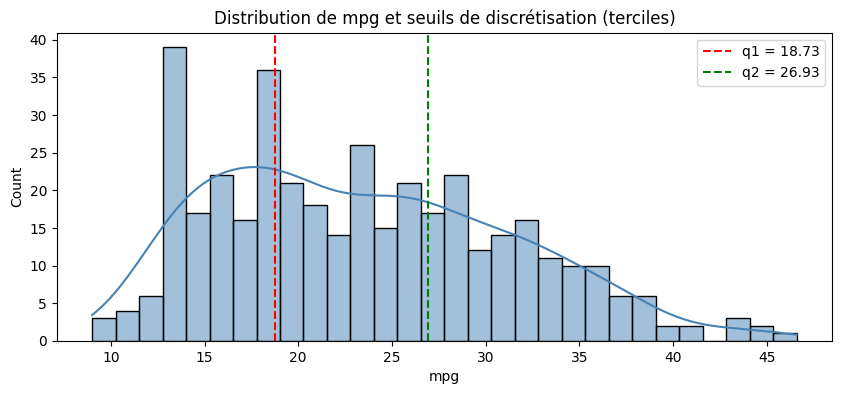

In [58]:
# Visualisation de la distribution de mpg et des seuils choisis
plt.figure(figsize=(10, 4))

sns.histplot(df["mpg"], bins=30, kde=True, color="steelblue")
plt.axvline(q1, color="red", linestyle="--", label=f"q1 = {q1:.2f}")
plt.axvline(q2, color="green", linestyle="--", label=f"q2 = {q2:.2f}")
plt.title("Distribution de mpg et seuils de discrétisation (terciles)")
plt.xlabel("mpg")
plt.legend()
plt.show()

In [59]:
def classer_mpg(mpg):
    if mpg <= q1:
        return "faible"
    elif mpg <= q2:
        return "moyenne"
    else:
        return "élevée"

In [60]:
df["classe"] = df["mpg"].apply(classer_mpg)

In [61]:
df[["mpg", "classe"]]

,mpg,classe
0,18.0,faible
1,15.0,faible
2,18.0,faible
3,16.0,faible
4,17.0,faible
...,...,...
393,27.0,élevée
394,44.0,élevée
395,32.0,élevée
396,28.0,élevée


In [62]:
print(df["classe"].value_counts()) 

classe
faible     131
élevée     131
moyenne    130
Name: count, dtype: int64


Notre objectif est maintenant de prédire la classe à partir des caractéristiques du véhicule. 

On va exclure mpg de X parce que c'est précisément ce que notre modèle doit prédire.

Et également exclure name, car le nom du véhicule n'est pas une caractéristique mécanique que nous souhaitons exploiter.

In [63]:
X = df.drop(columns=["mpg", "classe", "name"])
y = df["classe"]

On doit transformer origin comme c'est une variable catégorielle. Pour cela on utilise get_dummies()

In [64]:
X = pd.get_dummies(X, columns=["origin"], dtype=int)

Maintenant on transformer les classes (faible, moyenne, élevée) en nombres

In [65]:
y = y.map({
    "faible": 0,
    "moyenne": 1,
    "élevée": 2
})

### Séparer données d'entraînement et de test

In [66]:
from sklearn.model_selection import train_test_split


In [67]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

### Standardisation des données

Comme les features n'ont pas les memes échelles, on doit les standariser.


In [68]:
from sklearn.preprocessing import StandardScaler

In [69]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test) #On ne fait pas fit sur le test : ça ferait apprendre au scaler des informations provenant du test. Et donc Les deux ensembles seraient standardisés avec des règles différentes.

# SVC linéaire avec scikit-learn

On commence par le noyau **linéaire** : il cherche un hyperplan qui sépare les classes. C'est le cas le plus simple et le plus interprétable.

In [70]:
from sklearn.svm import SVC

In [71]:
model_linear = SVC(kernel="linear", C=1 )

model_linear.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [72]:
y_pred = model_linear.predict(X_test)

### Évaluer le modèle

On utilise trois métriques complémentaires :
- **Accuracy** : % de bonnes prédictions globales.
- **Matrice de confusion** : montre *où* le modèle se trompe (quelles classes sont confondues).
- **Classification report** : precision / recall / f1 **par classe** — essentiel pour voir si une classe est sacrifiée.

In [73]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix)

In [74]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy :", accuracy)


Accuracy : 0.7974683544303798


In [75]:
print(confusion_matrix(y_test, y_pred))

[[20  7  0]
 [ 1 22  3]
 [ 0  5 21]]


In [76]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.95      0.74      0.83        27
           1       0.65      0.85      0.73        26
           2       0.88      0.81      0.84        26

    accuracy                           0.80        79
   macro avg       0.82      0.80      0.80        79
weighted avg       0.83      0.80      0.80        79



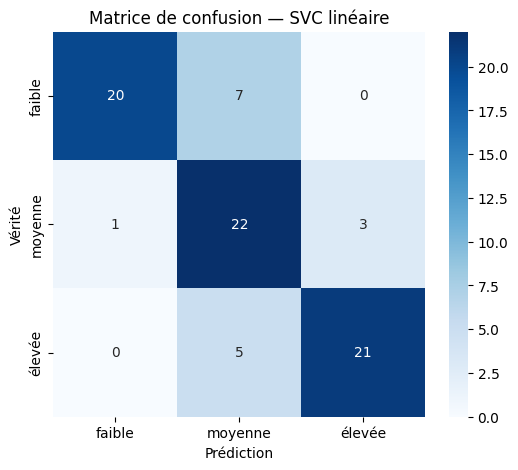

In [77]:
# Visualisation de la matrice de confusion
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["faible", "moyenne", "élevée"],
            yticklabels=["faible", "moyenne", "élevée"])
plt.xlabel("Prédiction")
plt.ylabel("Vérité")
plt.title("Matrice de confusion — SVC linéaire")
plt.show()

## SVC avec noyau RBF

Le noyau **RBF** (Radial Basis Function) projette implicitement les données dans un espace de dimension infinie, permettant des frontières **non linéaires**. 

In [78]:
model_rbf = SVC( kernel="rbf", C=1)

model_rbf.fit(X_train, y_train)
y_pred_rbf = model_rbf.predict(X_test)

### Évaluer le modèle

In [79]:
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print("Accuracy RBF :", accuracy_rbf)

Accuracy RBF : 0.7848101265822784


In [80]:
print("Rapport de classification RBF :")
print(classification_report(y_test, y_pred_rbf,
      target_names=["faible", "moyenne", "élevée"]))

Rapport de classification RBF :
              precision    recall  f1-score   support

      faible       0.95      0.67      0.78        27
     moyenne       0.62      0.88      0.73        26
      élevée       0.91      0.81      0.86        26

    accuracy                           0.78        79
   macro avg       0.83      0.79      0.79        79
weighted avg       0.83      0.78      0.79        79



## Comparer les deux modèles

In [81]:
print("SVC linéaire :", accuracy_score(y_test, y_pred))
print("SVC RBF      :", accuracy_score(y_test, y_pred_rbf))

SVC linéaire : 0.7974683544303798
SVC RBF      : 0.7848101265822784


## Interprétation :

Le modèle SVC avec un noyau linéaire obtient une accuracy de 79.75 %, légèrement supérieure à celle du modèle SVC avec noyau RBF (78.48 %).

Cela signifie que le modèle linéaire a correctement classé environ 80 % des véhicules de l'ensemble de test.

Dans notre cas, le noyau linéaire donne de meilleurs résultats que le noyau RBF. Cela peut indiquer que les relations entre les caractéristiques des véhicules et les classes de consommation sont suffisamment bien représentées par une séparation linéaire.

Cependant, la différence entre les deux résultats est faible (environ 1.27 point de pourcentage). On ne peut donc pas conclure que le modèle linéaire est systématiquement meilleur.

## Conclusion : 
Pour cette configuration et cette séparation des données, le SVC linéaire est légèrement plus performant que le SVC RBF. Le choix du noyau dépend toutefois des caractéristiques des données et des paramètres du modèle.




# Classification SVC sans scikit learn





Un SVM classique est naturellement binaire : il sépare deux classes.

Mais dans ce devoire, on 3 classes. Donc, il suffit d'utiliser une méthode simple appelée One-vs-Rest :

In [82]:
def predict_one(x, w, b):
    score = np.dot(w, x) + b

    if score >= 0:
        return 1
    else:
        return -1

1. Fonction pour entraîner un SVM binaire


In [83]:
def train_svm(X, y, learning_rate=0.001, lambda_param=0.01, n_iterations=1000):

    n_samples, n_features = X.shape

    # Initialisation
    w = np.zeros(n_features)
    b = 0

    # Apprentissage
    for _ in range(n_iterations):

        for i in range(n_samples):

            x_i = X[i]
            y_i = y[i]

            # Calcul du score
            score = np.dot(w, x_i) + b

            # Vérification de la marge
            if y_i * score >= 1:

                # Pas besoin de corriger avec les données
                w = w - learning_rate * (2 * lambda_param * w)

            else:

                # Correction de w
                w = w - learning_rate * (
                    2 * lambda_param * w - y_i * x_i
                )

                # Correction de b
                b = b + learning_rate * y_i

    return w, b

2. Fonction de prédiction

In [84]:
def predict_svm(X, w, b):

    predictions = []

    for x in X:

        score = np.dot(w, x) + b

        if score >= 0:
            predictions.append(1)
        else:
            predictions.append(-1)

    return np.array(predictions)

Pour chaque classe, on construit un problème binaire :
- SVM 0 : classe 0 contre le reste
- SVM 1 : classe 1 contre le reste
- SVM 2 : classe 2 contre le reste

In [85]:
classes = [0, 1, 2]

modeles = {}

for classe in classes:

    # Créer les labels binaires
    y_binary = np.where(
        y_train == classe,
        1,
        -1
    )

    # Entraîner le SVM
    w, b = train_svm(
        X_train,
        y_binary
    )

    # Sauvegarder le modèle
    modeles[classe] = (w, b)

Maintenant, pour chaque voiture du test, les trois SVM vont donner un score.

In [86]:
def predict_multiclass(X, modeles):

    predictions = []

    for x in X:

        scores = []

        for classe in [0, 1, 2]:

            w, b = modeles[classe]

            score = np.dot(w, x) + b

            scores.append(score)

        # Choisir la classe avec le score le plus élevé
        classe_predite = np.argmax(scores)

        predictions.append(classe_predite)

    return np.array(predictions)

In [87]:
y_pred = predict_multiclass(X_test,modeles)

In [88]:
accuracy = np.mean(y_pred == y_test)

print("Accuracy SVM sans scikit-learn :", accuracy)

Accuracy SVM sans scikit-learn : 0.759493670886076


In [89]:
# Comparaison des vraies classes et des prédictions

print("Vraies classes :", y_test[:15])
print("Prédictions    :", y_pred[:15])

Vraies classes : 344    2
265    0
47     1
343    2
147    1
304    2
1      0
178    1
225    0
92     0
213    0
270    1
45     0
160    0
272    1
Name: classe, dtype: int64
Prédictions    : [2 0 0 2 2 2 0 1 0 0 0 2 0 0 2]


## Noyau RBF

In [90]:
def rbf_kernel(x1, x2, gamma=0.01):

    distance = np.sum((x1 - x2) ** 2)

    return np.exp(-gamma * distance)

### Fonction d'entraînement RBF

In [91]:
def train_svm_rbf(X, y, C=1, gamma=0.01,
                  learning_rate=0.001,
                  n_iterations=1000):

    n_samples = X.shape[0]

    # Construire la matrice du noyau
    K = np.zeros((n_samples, n_samples))

    for i in range(n_samples):
        for j in range(n_samples):
            K[i, j] = rbf_kernel(X[i], X[j], gamma)

    # Initialiser les coefficients
    alpha = np.zeros(n_samples)

    # Apprentissage
    for _ in range(n_iterations):

        for i in range(n_samples):

            prediction = np.sum(alpha * y * K[:, i])

            gradient = 1 - y[i] * prediction

            alpha[i] = alpha[i] + learning_rate * gradient

            alpha[i] = max(0, min(C, alpha[i]))

    # Calcul du biais
    scores = K @ (alpha * y)

    support_indices = np.where(alpha > 1e-5)[0]

    b = np.mean(
        y[support_indices] - scores[support_indices]
    )

    return alpha, b, X, y

### Fonction de prédiction RBF

In [92]:
def predict_svm_rbf(X_test, model):

    alpha, b, X_train, y_train = model

    predictions = []

    for x in X_test:

        score = 0

        for i in range(len(X_train)):

            score += (
                alpha[i] *
                y_train[i] *
                rbf_kernel(X_train[i], x)
            )

        score += b

        if score >= 0:
            predictions.append(1)
        else:
            predictions.append(-1)

    return np.array(predictions)

In [93]:
classes = [0, 1, 2]

modeles_rbf = {}

for classe in classes:

    y_binary = np.where(
        y_train == classe,
        1,
        -1
    )

    model = train_svm_rbf(
        X_train,
        y_binary
    )

    modeles_rbf[classe] = model

In [94]:
def predict_multiclass_rbf(X, modeles):

    predictions = []

    for x in X:

        scores = []

        for classe in [0, 1, 2]:

            alpha, b, X_train, y_train = modeles[classe]

            score = 0

            for i in range(len(X_train)):

                score += (
                    alpha[i] *
                    y_train[i] *
                    rbf_kernel(X_train[i], x)
                )

            score += b

            scores.append(score)

        predictions.append(np.argmax(scores))

    return np.array(predictions)

In [95]:
y_pred_rbf = predict_multiclass_rbf(X_test,modeles_rbf)

accuracy_rbf = np.mean(y_pred_rbf == y_test)

print("Accuracy SVM RBF :", accuracy_rbf)

Accuracy SVM RBF : 0.6962025316455697


## Analyse de l'écart important : 
l'implémentation from scratch RBF est nettement en dessous de sklearn. Cela **confirme** que l'optimisation utilisée n'est pas correcte pour un SVM à noyau. Un vrai SVM avec SMO atteindrait les performances de sklearn.
